In [30]:
from scipy.special import gammaln
from scipy.special import factorial
from math import log as mathlog # why not use np.log ?
import numpy as np
import matplotlib.pyplot as plt
from week05 import make_microstate_factory
import numpy as np
from collections import Counter
from scipy.special import xlogy          # xlogy(x, y) = x*log(y), and 0 when x = 0
from scipy.optimize import minimize_scalar
from scipy.integrate import quad
from scipy.stats import binom

In [31]:
microState = make_microstate_factory(N=2, L=3)
microState(2)
microState.total
microState(2).plot(ax)

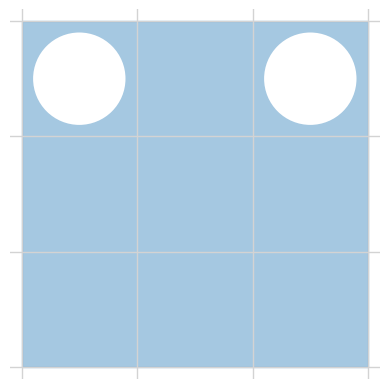

In [32]:
fig, ax = plt.subplots()
state = microState(1)
microState(1).plot(ax)

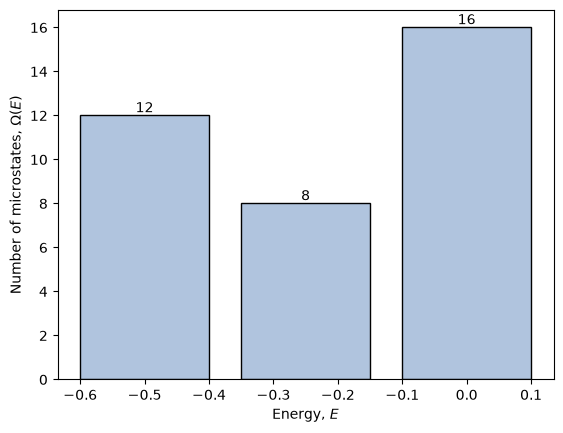

In [33]:
energies = [microState(i).energy for i in range(36)]

# round to avoid floating-point mismatches when grouping equal energies
counts = Counter(round(e, 6) for e in energies)
levels = sorted(counts)                    # should be 3 distinct values
omega = [counts[e] for e in levels]        # Ω(E) for each level

fig, ax = plt.subplots()
bars = ax.bar(levels, omega, width=0.2, color="lightsteelblue", edgecolor="black")
ax.bar_label(bars)                         # writes the count above each bar (like the "12")
ax.set_xlabel("Energy, $E$")
ax.set_ylabel("Number of microstates, $\\Omega(E)$")
plt.show()

In [ ]:
L = 6
N = 4
states = make_microstate_factory(N=N, L=L)
from math import comb


total = comb(L**2, N)   # C(36, 4)
print(total)

58905


58905 58905


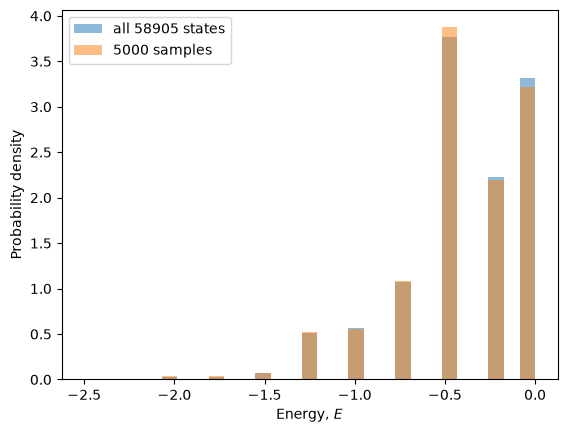

In [41]:
microState = make_microstate_factory(N=4, L=6)   # must give N=4, L=6

# 2. Take the total from the class itself, and check it against the binomial
total = microState(0).total
print(total, comb(6**2, 4))                 # both should be 58905

# 3. Full enumeration
all_energies = [microState(i).energy for i in range(total)]

# 4. Random sampling (microState() with no index draws a random state)
n_samples = 5000
sampled = [microState().energy for _ in range(n_samples)]

# 5. Compare the two as normalized histograms
fig, ax = plt.subplots()
bins = np.linspace(min(all_energies), max(all_energies), 30)
ax.hist(all_energies, bins=bins, density=True, alpha=0.5, label=f"all {total} states")
ax.hist(sampled, bins=bins, density=True, alpha=0.5, label=f"{n_samples} samples")
ax.set_xlabel("Energy, $E$")
ax.set_ylabel("Probability density")
ax.legend()
plt.show()